# Task 1 — AAPL time-series preprocessing, EDA and forecasting

This notebook uses the complete dataset for dataset-level inspection and AAPL for the forecasting case. The forecast target is the next available trading session's `Close`. Run from the repository root.

In [1]:
from pathlib import Path
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
from formative_1.preprocessing import load_source, validate_and_clean
from formative_1.feature_engineering import make_features

raw = load_source()  # Or load_source('data/raw/stock_prices.csv')
print('Shape:', raw.shape)
print('Columns:', raw.columns)
print(
    'Date range:',
    raw.select(
        pl.col('Date').min().alias('earliest_date'),
        pl.col('Date').max().alias('latest_date')
    )
)
print('Exact duplicate rows:', raw.height - raw.unique().height)
display(raw.head())

Shape: (310122, 13)
Columns: ['Date', 'Open', 'High', 'Low', 'Close', 'Volume', 'Brand_Name', 'Ticker', 'Industry_Tag', 'Country', 'Dividends', 'Stock Splits', 'Capital Gains']
Date range: shape: (1, 2)
┌───────────────────────────┬───────────────────────────┐
│ earliest_date             ┆ latest_date               │
│ ---                       ┆ ---                       │
│ str                       ┆ str                       │
╞═══════════════════════════╪═══════════════════════════╡
│ 2000-01-03 00:00:00-05:00 ┆ 2025-07-03 00:00:00-04:00 │
└───────────────────────────┴───────────────────────────┘
Exact duplicate rows: 0


Date,Open,High,Low,Close,Volume,Brand_Name,Ticker,Industry_Tag,Country,Dividends,Stock Splits,Capital Gains
str,f64,f64,f64,f64,f64,str,str,str,str,f64,f64,f64
"""2025-07-03 00:00:00-04:00""",6.63,6.74,6.615,6.64,4.209664e6,"""peloton""","""PTON""","""fitness""","""usa""",0.0,0.0,null
"""2025-07-03 00:00:00-04:00""",106.75,108.370003,106.330101,107.339996,560190.0,"""crocs""","""CROX""","""footwear""","""usa""",0.0,0.0,null
"""2025-07-03 00:00:00-04:00""",122.629997,123.050003,121.550003,121.93,36600.0,"""adidas""","""ADDYY""","""apparel""","""germany""",0.0,0.0,null
"""2025-07-03 00:00:00-04:00""",221.705002,224.009995,221.360001,223.410004,2.9295154e7,"""amazon""","""AMZN""","""e-commerce""","""usa""",0.0,0.0,null
"""2025-07-03 00:00:00-04:00""",212.145004,214.649994,211.810104,213.550003,3.4697317e7,"""apple""","""AAPL""","""technology""","""usa""",0.0,0.0,null


## Dataset profile
Inspect null counts, data types, numerical distributions, and ticker/date duplication before making cleaning decisions. Do not interpret weekends or exchange holidays as missing trading observations.

In [2]:
print(raw.schema)
nulls = raw.null_count().transpose(include_header=True, header_name='column', column_names=['null_count'])
display(nulls)
numeric_cols = [c for c, dtype in raw.schema.items() if dtype.is_numeric()]
display(raw.select(numeric_cols).describe())
if {'Ticker', 'Date'}.issubset(raw.columns):
    duplicate_keys = (raw.group_by(['Ticker', 'Date']).len()
                      .filter(pl.col('len') > 1).sort('len', descending=True))
    display(duplicate_keys.head(20))

Schema({'Date': String, 'Open': Float64, 'High': Float64, 'Low': Float64, 'Close': Float64, 'Volume': Float64, 'Brand_Name': String, 'Ticker': String, 'Industry_Tag': String, 'Country': String, 'Dividends': Float64, 'Stock Splits': Float64, 'Capital Gains': Float64})


column,null_count
str,u32
"""Date""",0
"""Open""",0
"""High""",0
"""Low""",0
"""Close""",0
…,…
"""Industry_Tag""",0
"""Country""",0
"""Dividends""",0


statistic,Open,High,Low,Close,Volume,Dividends,Stock Splits,Capital Gains
str,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",310122.0,310122.0,310122.0,310122.0,310122.0,310122.0,310122.0,2.0
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,310120.0
"""mean""",76.325431,77.198011,75.434586,76.338032,2.2709e7,0.003643,0.000875,0.0
"""std""",141.68407,143.224109,140.063617,141.679129,8.5657e7,0.069905,0.115434,0.0
"""min""",0.0,0.0,0.0,0.198861,0.0,0.0,0.0,0.0
"""25%""",15.9325,16.163087,15.710284,15.94,1.379e6,0.0,0.0,0.0
"""50%""",35.408222,35.809893,34.982517,35.408009,4.591683e6,0.0,0.0,0.0
"""75%""",83.997962,84.915001,83.088611,84.0,1.21286e7,0.0,0.0,0.0
"""max""",3445.580078,3463.070068,3370.0,3427.610107,7.4216e9,15.0,50.0,0.0


Ticker,Date,len
str,str,u32
"""NFLX""","""2025-06-20 00:00:00-04:00""",2
"""AEO""","""2025-01-17 00:00:00-05:00""",2
"""DAL""","""2024-07-26 00:00:00-04:00""",2
"""MMM""","""2024-12-27 00:00:00-05:00""",2
"""FL""","""2025-05-30 00:00:00-04:00""",2
…,…,…
"""PG""","""2024-08-23 00:00:00-04:00""",2
"""TGT""","""2024-12-31 00:00:00-05:00""",2
"""BAMXF""","""2024-12-06 00:00:00-05:00""",2


In [ ]:
### Missing-Value Analysis

Missing values were examined across the 13 columns of the original dataset, which contains 310,122 observations.

The analysis identified that the `Capital Gains` column contains 310,120 missing values, representing approximately 99.999% of the dataset. This column provides almost no usable information and was therefore excluded from analyses requiring complete observations.

For the selected AAPL time series, preprocessing also ensured that the `Date` and `Close` columns contained no missing values. These columns are essential because the date establishes the chronological order of observations, while the closing price is the forecasting target.

The remaining missing values and their distribution were considered during preprocessing and feature engineering. The reduction from 6,408 cleaned AAPL observations to 6,378 feature-complete observations resulted from the initial observations needed to calculate lagged and rolling-window features.

Overall, missing-value analysis helped identify unsuitable variables and ensured that the forecasting dataset contained valid chronological observations and target values.

In [ ]:
### Duplicate-Record Analysis

Duplicate records were investigated using the combination of `Ticker` and `Date` as the identifying key for a stock's daily observation.

Although the original dataset contained no exact duplicate rows, some stock-date combinations appeared more than once. This distinction is important because records can share the same ticker and date while containing different numerical values.

For the selected AAPL time series, 62 dates contained duplicate observations, representing 124 records. Further inspection showed that the closing prices were consistent across duplicate records, although some other numerical variables, including Open, High, Low and Volume, differed.

To produce one observation per trading date, duplicate records were consolidated. The median was used for numerical market variables, while the first available value was retained for descriptive metadata. This produced a cleaned AAPL dataset containing 6,408 unique chronological observations.

This reconciliation provided a consistent time series for exploratory analysis and forecasting. However, using the median is a practical resolution strategy rather than confirmation of the original exchange-reported values, and this is acknowledged as a data-quality limitation.

In [19]:
missing_summary = pl.DataFrame([
    {
        "Column": col,
        "Missing_Count": raw[col].null_count(),
        "Missing_Percentage": round(
            raw[col].null_count() / raw.height * 100, 4
        )
    }
    for col in raw.columns
]).sort("Missing_Count", descending=True)

display(missing_summary)

Column,Missing_Count,Missing_Percentage
str,i64,f64
"""Capital Gains""",310120,99.9994
"""Date""",0,0.0
"""Open""",0,0.0
"""High""",0,0.0
"""Low""",0,0.0
…,…,…
"""Ticker""",0,0.0
"""Industry_Tag""",0,0.0
"""Country""",0,0.0


## Analytical question 1 — What is the long-term AAPL closing-price trend?
The line chart and 30-session moving average show the price level and its smoothed direction. The moving average is descriptive, not a guarantee of future direction.

Found 62 dates with duplicate observations.
Consolidated duplicate dates. Remaining observations: 6,408


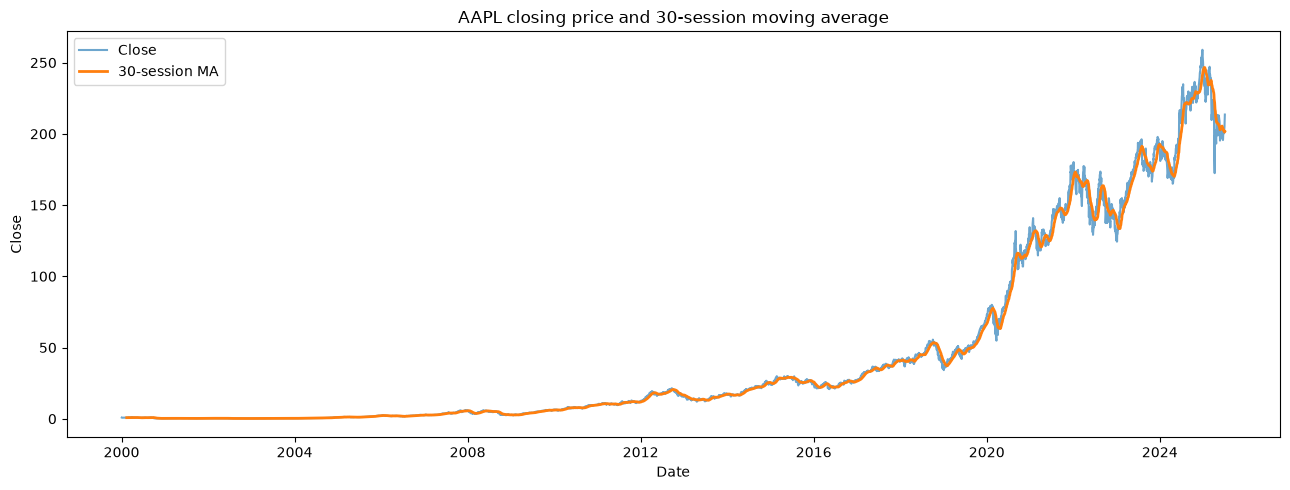

In [3]:
aapl = validate_and_clean(raw, 'AAPL')
aapl = aapl.with_columns(pl.col('Close').rolling_mean(window_size=30, min_samples=30).alias('MA_30'))
plt.figure(figsize=(13, 5))
plt.plot(aapl['Date'].to_list(), aapl['Close'].to_list(), label='Close', alpha=.65)
plt.plot(aapl['Date'].to_list(), aapl['MA_30'].to_list(), label='30-session MA', linewidth=2)
plt.title('AAPL closing price and 30-session moving average'); plt.xlabel('Date'); plt.ylabel('Close'); plt.legend(); plt.tight_layout(); plt.show()

The historical closing-price chart shows Apple's long-term price evolution between 2000 and 2025. The 30-session moving average smooths short-term fluctuations and makes longer-term trends easier to identify. The moving average also responds more slowly to sudden price changes, illustrating the trade-off between smoothing and responsiveness.

## Analytical question 2 — Do daily returns vary by month or year?
Daily returns are more suitable than raw prices for comparing percentage movements across different price levels. Monthly and annual averages can be affected by outliers and should not be treated as proof of a recurring seasonal effect.

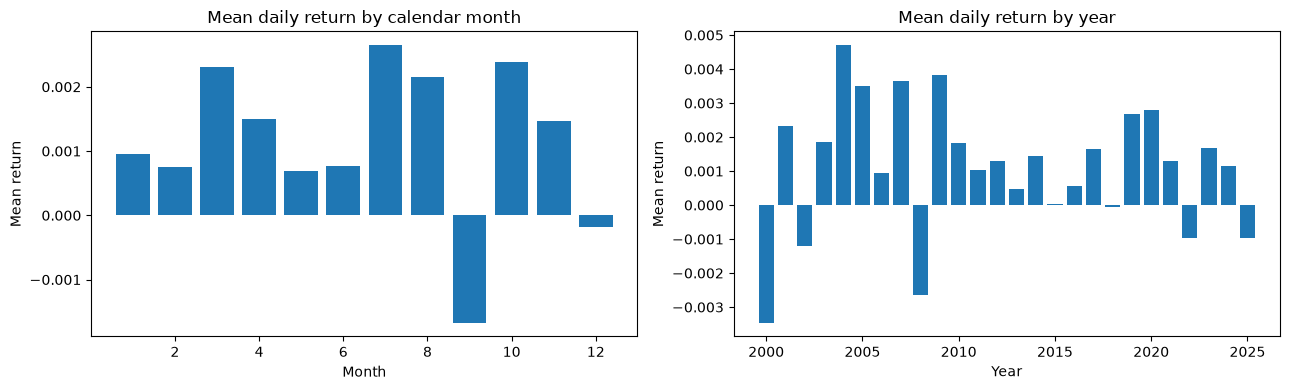

In [4]:
returns = aapl.with_columns((pl.col('Close') / pl.col('Close').shift(1) - 1).alias('Daily_Return')).drop_nulls('Daily_Return')
monthly = returns.with_columns(pl.col('Date').dt.month().alias('Month')).group_by('Month').agg(pl.col('Daily_Return').mean().alias('Mean_Return')).sort('Month')
annual = returns.with_columns(pl.col('Date').dt.year().alias('Year')).group_by('Year').agg(pl.col('Daily_Return').mean().alias('Mean_Return')).sort('Year')
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(monthly['Month'].to_list(), monthly['Mean_Return'].to_list()); axes[0].set(title='Mean daily return by calendar month', xlabel='Month', ylabel='Mean return')
axes[1].bar(annual['Year'].to_list(), annual['Mean_Return'].to_list()); axes[1].set(title='Mean daily return by year', xlabel='Year', ylabel='Mean return')
plt.tight_layout(); plt.show()

The monthly and annual return analysis reveals variation in Apple's average daily returns across different periods.

At the monthly level, July recorded the highest average daily return (0.2647%), followed by October (0.2380%) and March (0.2304%). September recorded the lowest average daily return (-0.1670%), while December also showed a slightly negative average (-0.0184%).

At the annual level, 2004 had the highest average daily return (0.4702%), followed by 2009 (0.3819%). In contrast, 2000 recorded the lowest average daily return (-0.3457%), followed by 2008 (-0.2646%).

These results indicate that Apple's historical returns varied across months and years. However, differences in historical averages alone do not establish a recurring seasonal pattern or guarantee similar future performance.

## Analytical question 3 — How are price, volume, and corporate-action variables related?
The correlation matrix is descriptive. Same-session OHLC values are mechanically related, and correlation does not establish causation or out-of-sample predictive value.

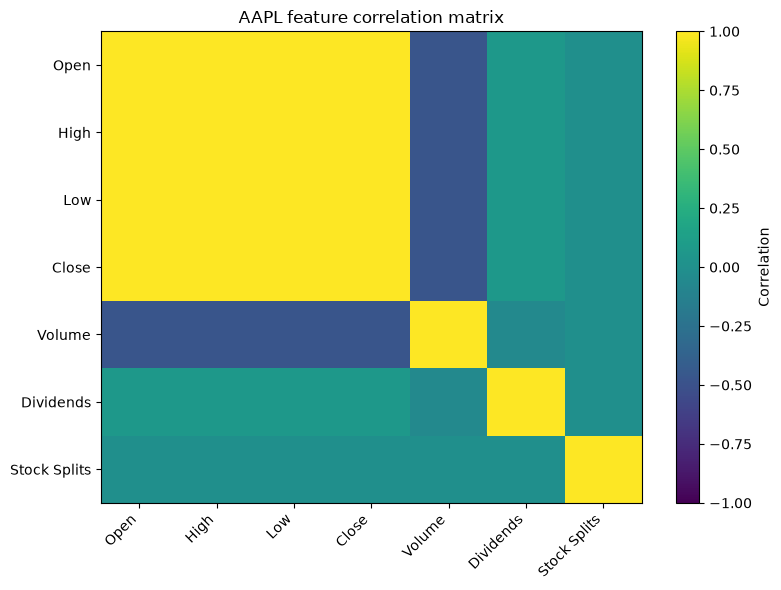

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Open,1.000000,0.999922,0.999925,0.999838,-0.469913,0.067988,-0.000490
High,0.999922,1.000000,0.999895,0.999928,-0.469505,0.067653,-0.000301
Low,0.999925,0.999895,1.000000,0.999923,-0.470441,0.067978,-0.000514
Close,0.999838,0.999928,0.999923,1.000000,-0.469952,0.067836,-0.000333
Volume,-0.469913,-0.469505,-0.470441,-0.469952,1.000000,-0.055431,-0.001526
Dividends,0.067988,0.067653,0.067978,0.067836,-0.055431,1.000000,-0.001871
Stock Splits,-0.000490,-0.000301,-0.000514,-0.000333,-0.001526,-0.001871,1.000000


In [5]:
corr_cols = ['Open', 'High', 'Low', 'Close', 'Volume', 'Dividends', 'Stock Splits']
corr = aapl.select(corr_cols).to_pandas().corr(numeric_only=True)
plt.figure(figsize=(8, 6)); plt.imshow(corr, aspect='auto', vmin=-1, vmax=1); plt.colorbar(label='Correlation')
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha='right'); plt.yticks(range(len(corr.index)), corr.index)
plt.title('AAPL feature correlation matrix'); plt.tight_layout(); plt.show()
display(corr)

The OHLC variables have extremely strong positive correlations, with correlations between Close and High, Low and Open all exceeding 0.999. This is expected because these variables describe different prices within the same trading session. Trading volume has a moderate negative correlation with closing price (-0.470), while dividends have a weak positive correlation (0.068). Stock splits show almost no linear correlation with closing price (-0.0003). These associations are descriptive and do not establish causation.

## Analytical question 4 — How strongly are past closing prices associated with the current close?
Lagged close values are prior trading-session observations. Price-level autocorrelation can be high because stock prices are non-stationary; it does not by itself imply profitable predictability.

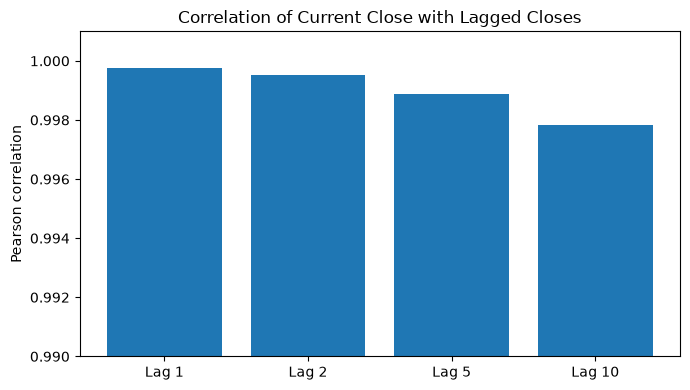

{'Lag 1': np.float64(0.9997554210741334), 'Lag 2': np.float64(0.9995202369298245), 'Lag 5': np.float64(0.9988678761683704), 'Lag 10': np.float64(0.9978341636267124)}


In [16]:

import numpy as np
import matplotlib.pyplot as plt

# Ensure chronological order
aapl = aapl.sort("Date")

# Extract closing prices
close = aapl["Close"].to_numpy()

# Calculate lag correlations
lag_corr = {}

for k in [1, 2, 5, 10]:
    current = close[k:]
    previous = close[:-k]

    lag_corr[f"Lag {k}"] = np.corrcoef(
        current, previous
    )[0, 1]

# Plot
plt.figure(figsize=(7, 4))
plt.bar(list(lag_corr.keys()), list(lag_corr.values()))
plt.ylim(0.99, 1.001)
plt.title("Correlation of Current Close with Lagged Closes")
plt.ylabel("Pearson correlation")
plt.tight_layout()
plt.show()

print(lag_corr)


The lag correlation analysis reveals an extremely strong positive relationship between Apple's current closing price and its previous closing prices. The correlation decreases gradually from 0.9998 at lag 1 to 0.9978 at lag 10. This indicates substantial persistence in the historical price series. However, these high correlations partly reflect the long-term trend and non-stationarity of stock prices. Therefore, high price-level autocorrelation should not be interpreted as evidence of equally strong predictability in future returns.

## Analytical question 5 — How do short-, medium-, and long-window moving averages behave?
Moving averages summarize recent price history at different horizons. They are lagging indicators and use only observations available up to the current session.

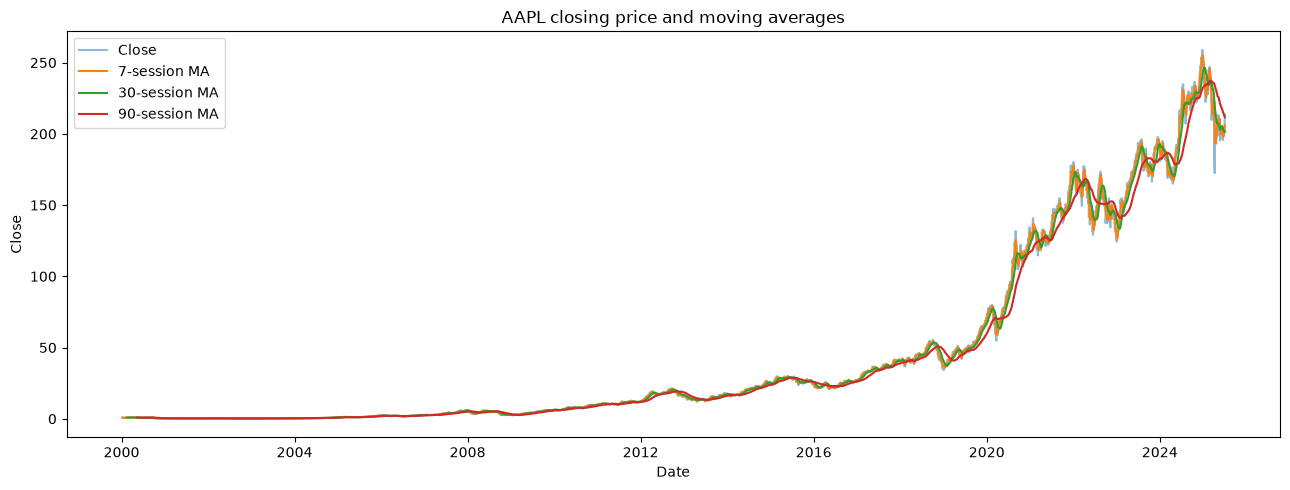

In [7]:
ma = aapl.with_columns(*[pl.col('Close').rolling_mean(window_size=w, min_samples=w).alias(f'MA_{w}') for w in [7, 30, 90]])
plt.figure(figsize=(13, 5)); plt.plot(ma['Date'].to_list(), ma['Close'].to_list(), label='Close', alpha=.5)
for w in [7, 30, 90]: plt.plot(ma['Date'].to_list(), ma[f'MA_{w}'].to_list(), label=f'{w}-session MA')
plt.title('AAPL closing price and moving averages'); plt.xlabel('Date'); plt.ylabel('Close'); plt.legend(); plt.tight_layout(); plt.show()

The 7-session moving average responds more closely to recent price movements, while the 30-session and 90-session moving averages produce progressively smoother trends. Longer windows reduce short-term noise but introduce greater lag when prices change direction. This demonstrates why moving averages are useful for understanding different time horizons in financial time series.

## Analytical question 6 — Is trading volume associated with the magnitude of daily returns?
Absolute daily return is used as a simple proxy for the magnitude of a price move. It is not a complete measure of volatility.

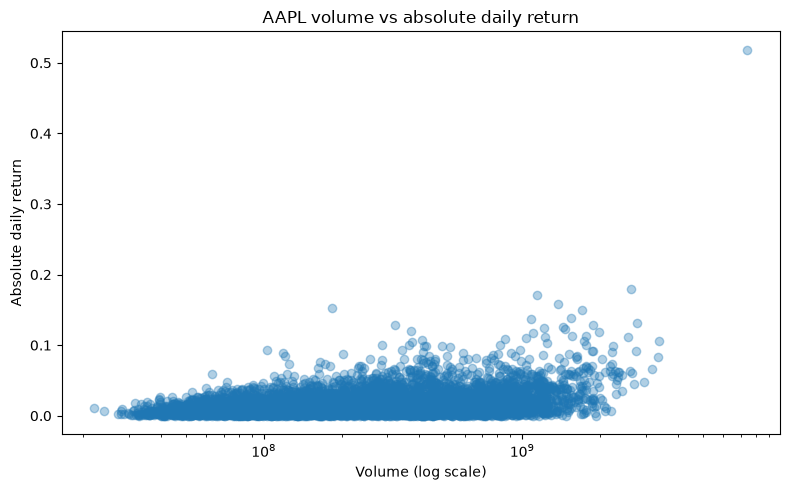

Correlation: 0.44138496112935494


In [8]:
volume_returns = returns.with_columns(pl.col('Daily_Return').abs().alias('Absolute_Return'))
plt.figure(figsize=(8, 5)); plt.scatter(volume_returns['Volume'].to_numpy(), volume_returns['Absolute_Return'].to_numpy(), alpha=.35)
plt.xscale('log'); plt.title('AAPL volume vs absolute daily return'); plt.xlabel('Volume (log scale)'); plt.ylabel('Absolute daily return'); plt.tight_layout(); plt.show()
print('Correlation:', volume_returns.select(pl.corr('Volume', 'Absolute_Return')).item())

The relationship between trading volume and absolute daily returns was investigated to determine whether periods of higher trading activity are associated with larger price movements.

The Pearson correlation coefficient was approximately 0.4414, indicating a moderate positive linear relationship. This suggests that trading sessions with higher trading volume tend to be associated with larger absolute daily price changes.

However, the relationship is not perfect, and trading volume alone cannot explain all daily price movements. The analysis is descriptive and does not establish a causal relationship.